# Lab Assignment - 7

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [6]:
dataset_path = "AT&T Dataset"

In [7]:
image_data = []
labels = []
image_paths = []

subject_folders = sorted(
    [folder for folder in os.listdir(dataset_path)
     if os.path.isdir(os.path.join(dataset_path, folder))
     and folder.startswith("s")],
    key=lambda folder: int(folder[1:])
)

for subject in subject_folders:
    subject_path = os.path.join(dataset_path, subject)

    image_files = sorted(
        [file for file in os.listdir(subject_path)
         if file.endswith(".pgm")],
        key=lambda file: int(os.path.splitext(file)[0])
    )

    for file in image_files:
        file_path = os.path.join(subject_path, file)

        image = Image.open(file_path).convert("L")
        image_array = np.array(image)

        image_data.append(image_array.flatten())
        labels.append(int(subject[1:]))
        image_paths.append(file_path)

X = np.array(image_data)
y = np.array(labels)

print("Number of images:", X.shape[0])
print("Features per image:", X.shape[1])
print("Number of subjects:", len(np.unique(y)))
print("Image dimensions:", image_array.shape)
print("Pixel intensity range:", X.min(), "to", X.max())
print("Labels shape:", y.shape)

Number of images: 400
Features per image: 10304
Number of subjects: 40
Image dimensions: (112, 92)
Pixel intensity range: 0 to 251
Labels shape: (400,)


In [8]:
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)

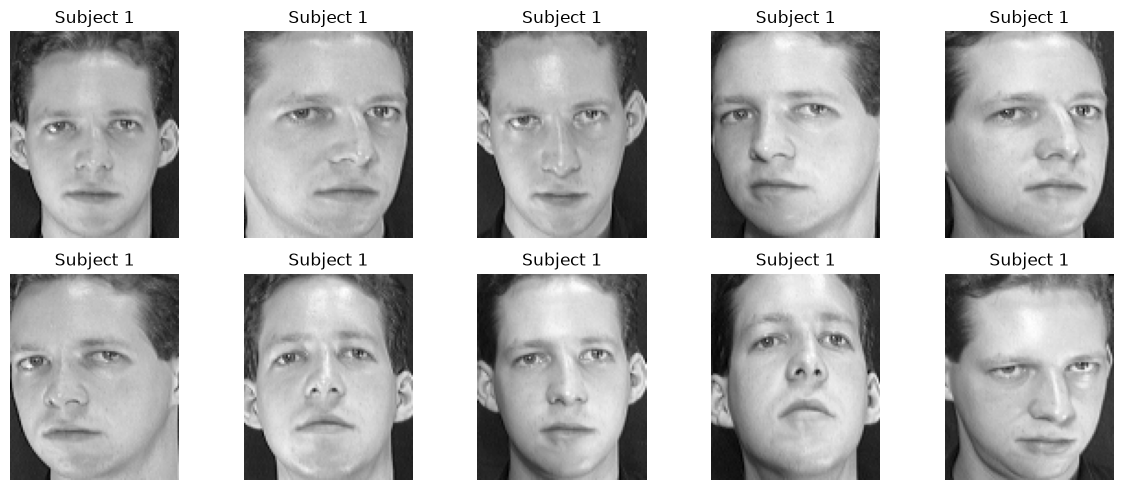

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(112, 92), cmap="gray")
    ax.set_title(f"Subject {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.savefig("outputs/figures/sample_faces.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in testing:", len(np.unique(y_test)))

Training set: (320, 10304)
Testing set: (80, 10304)
Subjects in training: 40
Subjects in testing: 40


Mean face shape: (10304,)
Centered training data: (320, 10304)
Centered testing data: (80, 10304)


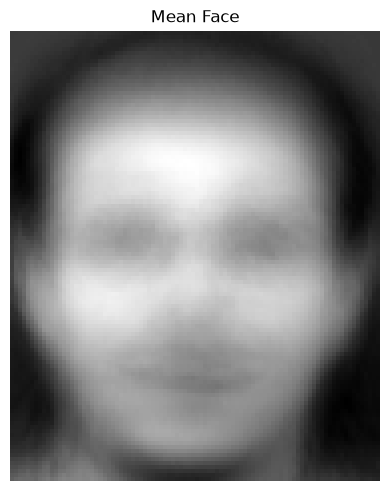

In [11]:
mean_face = np.mean(X_train, axis=0)
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Mean face shape:", mean_face.shape)
print("Centered training data:", X_train_centered.shape)
print("Centered testing data:", X_test_centered.shape)

mean_face_image = mean_face.reshape(112, 92)

plt.figure(figsize=(4, 5))
plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.tight_layout()
plt.savefig("outputs/figures/mean_face.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
U, S, Vt = np.linalg.svd(X_train_centered, full_matrices=False)

eigenfaces = Vt
eigenvalues = (S ** 2) / (len(X_train) - 1)

explained_variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_variance = np.cumsum(explained_variance_ratio)

print("Eigenfaces shape:", eigenfaces.shape)
print("Eigenvalues shape:", eigenvalues.shape)
print("Variance explained by first 5 components:")
print(explained_variance_ratio[:5])

Eigenfaces shape: (320, 10304)
Eigenvalues shape: (320,)
Variance explained by first 5 components:
[0.17940463 0.12889009 0.06810935 0.05425943 0.05041211]


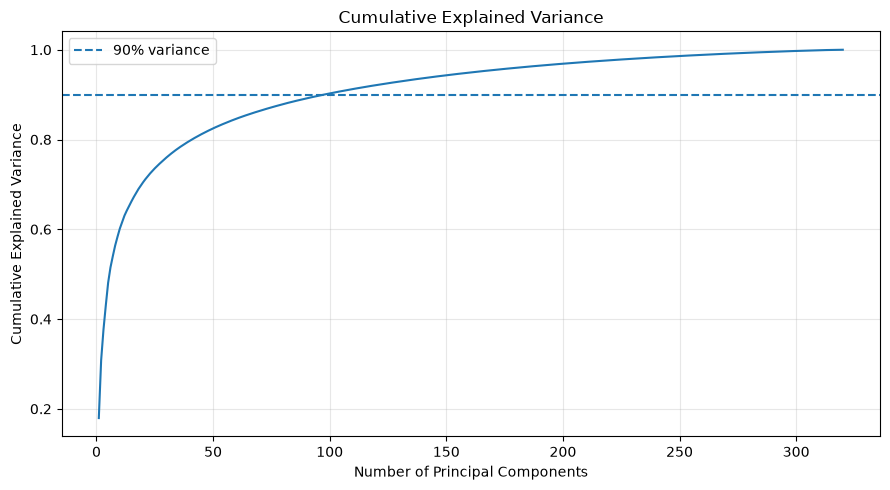

Components needed for 90% variance: 98
Variance retained: 0.9005854818500819


In [13]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(y=0.90, linestyle="--", label="90% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/figures/cumulative_explained_variance.png",
            dpi=300, bbox_inches="tight")
plt.show()

n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Components needed for 90% variance:", n_components_90)
print("Variance retained:", cumulative_variance[n_components_90 - 1])

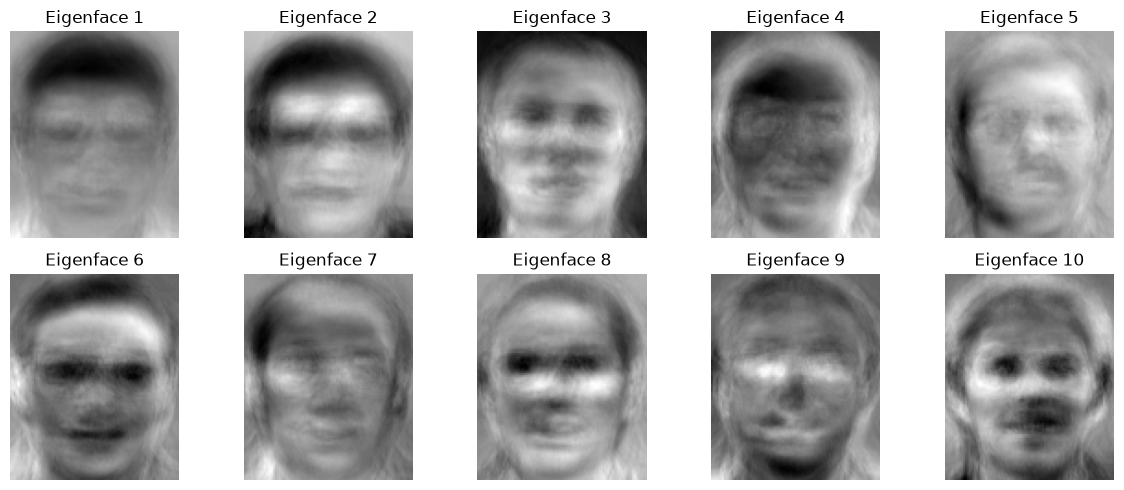

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(eigenfaces[i].reshape(112, 92), cmap="gray")
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.savefig("outputs/figures/first_10_eigenfaces.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [15]:
k = n_components_90

X_train_pca = X_train_centered @ eigenfaces[:k].T
X_test_pca = X_test_centered @ eigenfaces[:k].T

print("Number of components:", k)
print("Training PCA shape:", X_train_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)

Number of components: 98
Training PCA shape: (320, 98)
Testing PCA shape: (80, 98)


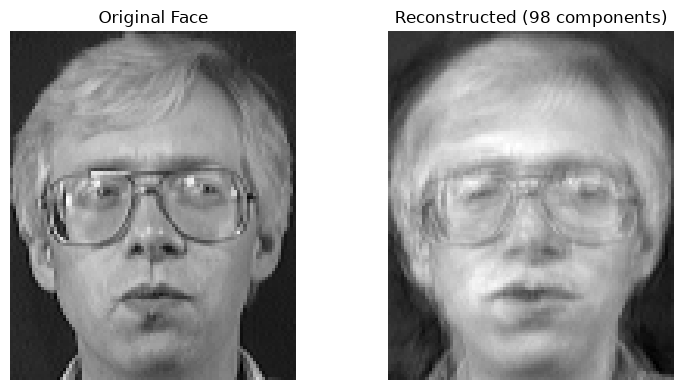

Reconstruction MSE: 307.39950275285673
Original features: 10304
Reduced features: 98
Feature reduction: 99.05 %


In [16]:
sample_index = 0

original_face = X_test[sample_index]
reconstructed_face = (
    X_test_pca[sample_index] @ eigenfaces[:k] + mean_face
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original_face.reshape(112, 92), cmap="gray")
axes[0].set_title("Original Face")
axes[0].axis("off")

axes[1].imshow(
    np.clip(reconstructed_face.reshape(112, 92), 0, 255),
    cmap="gray"
)
axes[1].set_title(f"Reconstructed ({k} components)")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("outputs/figures/face_reconstruction.png",
            dpi=300, bbox_inches="tight")
plt.show()

mse = np.mean((original_face - reconstructed_face) ** 2)
print("Reconstruction MSE:", mse)
print("Original features:", X.shape[1])
print("Reduced features:", k)
print("Feature reduction:", round((1 - k / X.shape[1]) * 100, 2), "%")

In [17]:
np.savez(
    "outputs/pca_face_representation.npz",
    X_train_pca=X_train_pca,
    X_test_pca=X_test_pca,
    y_train=y_train,
    y_test=y_test,
    mean_face=mean_face,
    eigenfaces=eigenfaces[:k],
    n_components=k
)
print("PCA representation saved successfully.")
print("Training representation:", X_train_pca.shape)
print("Testing representation:", X_test_pca.shape)

PCA representation saved successfully.
Training representation: (320, 98)
Testing representation: (80, 98)


In [18]:
distances = np.sqrt(
    np.sum(
        (X_test_pca[:, np.newaxis, :] - X_train_pca[np.newaxis, :, :]) ** 2,
        axis=2
    )
)
nearest_indices = np.argmin(distances, axis=1)
y_pred_pca = y_train[nearest_indices]
accuracy_pca = np.mean(y_pred_pca == y_test)
print("PCA nearest-neighbor accuracy:", round(accuracy_pca * 100, 2), "%")
print("Correct predictions:", np.sum(y_pred_pca == y_test), "out of", len(y_test))

PCA nearest-neighbor accuracy: 95.0 %
Correct predictions: 76 out of 80


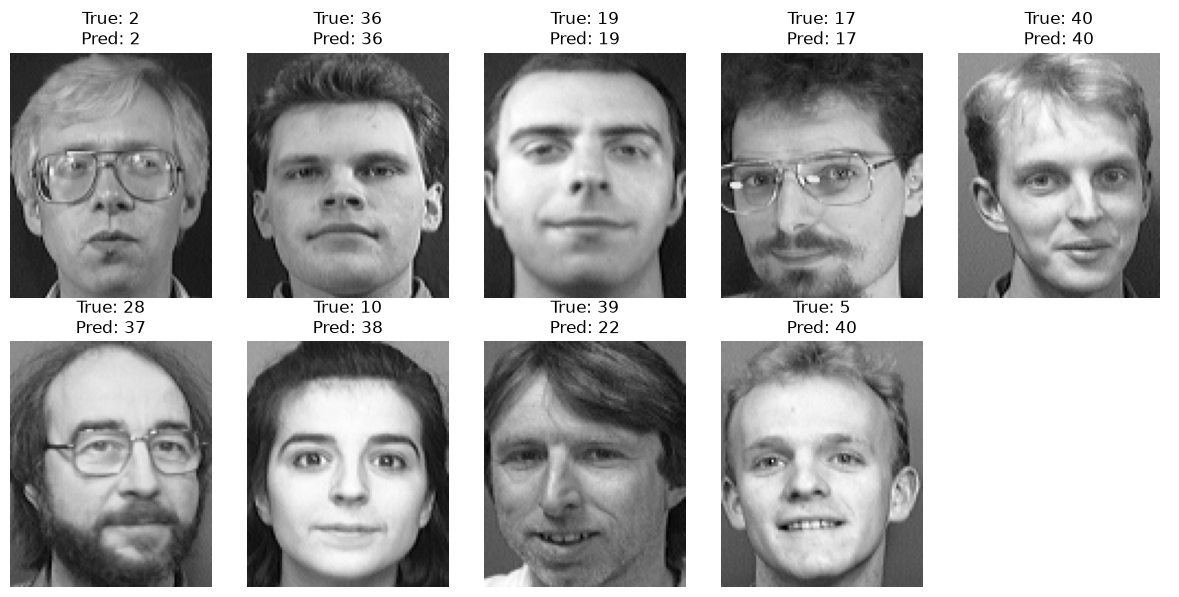

Correct examples available: 76
Incorrect examples available: 4


In [19]:
correct = np.where(y_pred_pca == y_test)[0]
incorrect = np.where(y_pred_pca != y_test)[0]

selected = list(correct[:5]) + list(incorrect[:5])

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    if i < len(selected):
        idx = selected[i]
        ax.imshow(X_test[idx].reshape(112, 92), cmap="gray")
        ax.set_title(
            f"True: {y_test[idx]}\nPred: {y_pred_pca[idx]}"
        )
        ax.axis("off")
    else:
        ax.axis("off")

plt.tight_layout()
plt.savefig("outputs/figures/recognition_examples.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Correct examples available:", len(correct))
print("Incorrect examples available:", len(incorrect))

In [20]:
raw_distances = np.sqrt(
    np.sum(
        (X_test[:, np.newaxis, :] - X_train[np.newaxis, :, :]) ** 2,
        axis=2
    )
)

raw_nearest_indices = np.argmin(raw_distances, axis=1)
y_pred_raw = y_train[raw_nearest_indices]

accuracy_raw = np.mean(y_pred_raw == y_test)

print("Raw-pixel nearest-neighbor accuracy:", round(accuracy_raw * 100, 2), "%")
print("PCA nearest-neighbor accuracy:", round(accuracy_pca * 100, 2), "%")

Raw-pixel nearest-neighbor accuracy: 100.0 %
PCA nearest-neighbor accuracy: 95.0 %


In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train_pca, y_train)
y_pred_knn = knn.predict(X_test_pca)

svm = SVC(kernel="linear")
svm.fit(X_train_pca, y_train)
y_pred_svm = svm.predict(X_test_pca)

print("PCA nearest-neighbor:", round(accuracy_pca * 100, 2), "%")
print("KNN accuracy:", round(accuracy_score(y_test, y_pred_knn) * 100, 2), "%")
print("SVM accuracy:", round(accuracy_score(y_test, y_pred_svm) * 100, 2), "%")

PCA nearest-neighbor: 95.0 %
KNN accuracy: 95.0 %
SVM accuracy: 97.5 %


In [22]:
import pandas as pd

results = pd.DataFrame({
    "Method": [
        "Raw-pixel Nearest Neighbor",
        "PCA Nearest Neighbor",
        "KNN on PCA Features",
        "Linear SVM on PCA Features"
    ],
    "Accuracy (%)": [
        accuracy_raw * 100,
        accuracy_pca * 100,
        accuracy_score(y_test, y_pred_knn) * 100,
        accuracy_score(y_test, y_pred_svm) * 100
    ]
})

results.to_csv("outputs/tables/recognition_comparison.csv", index=False)
results

,Method,Accuracy (%)
0,Raw-pixel Nearest Neighbor,100.0
1,PCA Nearest Neighbor,95.0
2,KNN on PCA Features,95.0
3,Linear SVM on PCA Features,97.5


In [23]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

component_counts = [20, 50, 98, 150]
comparison = []

for k_test in component_counts:
    train_features = X_train_centered @ eigenfaces[:k_test].T
    test_features = X_test_centered @ eigenfaces[:k_test].T

    distances = np.sqrt(
        np.sum(
            (test_features[:, np.newaxis, :] -
             train_features[np.newaxis, :, :]) ** 2,
            axis=2
        )
    )
    pred_nn = y_train[np.argmin(distances, axis=1)]

    svm_model = SVC(kernel="linear")
    svm_model.fit(train_features, y_train)
    pred_svm = svm_model.predict(test_features)

    comparison.append({
        "Components": k_test,
        "Features Retained (%)": round(
            cumulative_variance[k_test - 1] * 100, 2
        ),
        "Feature Reduction (%)": round(
            (1 - k_test / X.shape[1]) * 100, 2
        ),
        "Nearest Neighbor Accuracy (%)": round(
            accuracy_score(y_test, pred_nn) * 100, 2
        ),
        "SVM Accuracy (%)": round(
            accuracy_score(y_test, pred_svm) * 100, 2
        )
    })

component_results = pd.DataFrame(comparison)
component_results.to_csv(
    "outputs/tables/pca_component_comparison.csv", index=False
)
component_results

,Components,Features Retained (%),Feature Reduction (%),Nearest Neighbor Accuracy (%),SVM Accuracy (%)
0,20,70.49,99.81,95.00,95.0
1,50,82.48,99.51,96.25,97.5
2,98,90.06,99.05,95.00,97.5
3,150,94.31,98.54,95.00,97.5


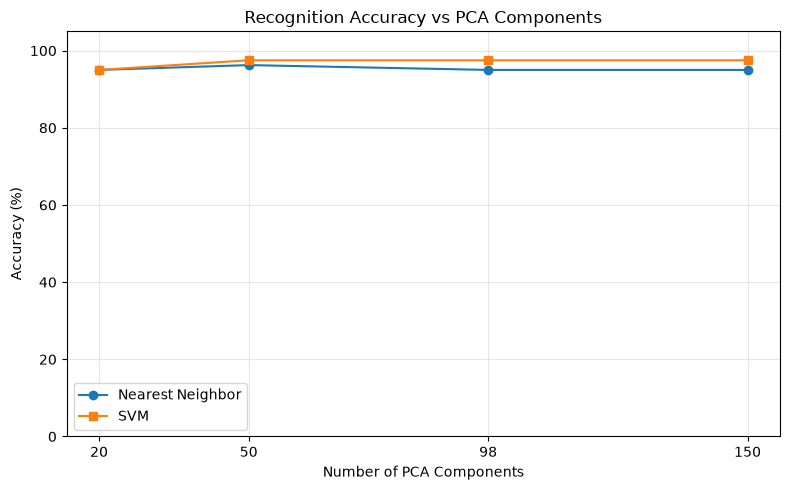

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    component_results["Components"],
    component_results["Nearest Neighbor Accuracy (%)"],
    marker="o",
    label="Nearest Neighbor"
)

plt.plot(
    component_results["Components"],
    component_results["SVM Accuracy (%)"],
    marker="s",
    label="SVM"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Accuracy (%)")
plt.title("Recognition Accuracy vs PCA Components")
plt.xticks(component_counts)
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("outputs/figures/accuracy_vs_components.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [27]:
original_size = X.nbytes
pca_size = X_train_pca.nbytes + X_test_pca.nbytes
storage_results = pd.DataFrame({
    "Representation": ["Original pixels", "PCA features (98 components)"],
    "Number of values": [X.size, X_train_pca.size + X_test_pca.size],
    "Storage (KB)": [
        round(original_size / 1024, 2),
        round(pca_size / 1024, 2)
    ]
})
storage_results.to_csv("outputs/tables/storage_comparison.csv", index=False)
print(storage_results.to_string(index=False))
print("Storage reduction (%):", round((1 - pca_size / original_size) * 100, 2))

              Representation  Number of values  Storage (KB)
             Original pixels           4121600       4025.00
PCA features (98 components)             39200        306.25
Storage reduction (%): 92.39


In [28]:
cov_small = X_train_centered @ X_train_centered.T
cov_eigenvalues = np.linalg.eigvalsh(cov_small)[::-1]
cov_eigenvalues = np.maximum(cov_eigenvalues, 0)

svd_eigenvalues = S ** 2

print("Largest 5 eigenvalues from SVD:")
print(svd_eigenvalues[:5])

print("\nLargest 5 eigenvalues from covariance eigendecomposition:")
print(cov_eigenvalues[:5])

print("\nMaximum absolute difference:")
print(np.max(np.abs(svd_eigenvalues - cov_eigenvalues)))

Largest 5 eigenvalues from SVD:
[9.19088224e+08 6.60302677e+08 3.48923556e+08 2.77970515e+08
 2.58260782e+08]

Largest 5 eigenvalues from covariance eigendecomposition:
[9.19088224e+08 6.60302677e+08 3.48923556e+08 2.77970515e+08
 2.58260782e+08]

Maximum absolute difference:
8.344650268554688e-07


In [29]:
cov_values, cov_vectors = np.linalg.eigh(cov_small)

order = np.argsort(cov_values)[::-1]
cov_values = np.maximum(cov_values[order], 0)
cov_vectors = cov_vectors[:, order]

n_compare = 10

cov_directions = X_train_centered.T @ cov_vectors[:, :n_compare]
cov_directions /= np.sqrt(cov_values[:n_compare])[None, :]

svd_directions = eigenfaces[:n_compare].T

similarities = np.abs(
    np.sum(cov_directions * svd_directions, axis=0)
)

direction_comparison = pd.DataFrame({
    "Component": np.arange(1, n_compare + 1),
    "Absolute Direction Similarity": similarities
})

direction_comparison.to_csv(
    "outputs/tables/direction_comparison.csv", index=False
)

print(direction_comparison.to_string(index=False))

 Component  Absolute Direction Similarity
         1                            1.0
         2                            1.0
         3                            1.0
         4                            1.0
         5                            1.0
         6                            1.0
         7                            1.0
         8                            1.0
         9                            1.0
        10                            1.0
